<img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/2/2c/HEIG-VD_logotype-baseline_rouge-rvb.png/330px-HEIG-VD_logotype-baseline_rouge-rvb.png" alt="Logo HEIG-VD" style="width: 200px;" align="right"/>

# Cours APN - Labo 2 : Cartes auto-organisatrices (SOM) de Kohonen

## Résumé

Le but de ce laboratoire est de réaliser une expérience de groupement avec des cartes auto-organisatrices.  Le code vous est fourni, y compris les deux librairies `kohonen.py` et `KohonenUtils.py`.  On vous demande de trouver une bonne paramétrisation de la carte, et d'expliquer brièvement quelques éléments de code.

## 1. Données

On considère une liste de 16 animaux, décrits à l'aide de 13 attributs booléens.  Les données sont fournies dans cette section.  Veuillez exécuter les cellules, inspecter les données, et répondre à la question finale.

In [1]:
%pip install pandas


Note: you may need to restart the kernel to use updated packages.


In [2]:
import KohonenUtils
import numpy as np
import pandas as pd
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
%matplotlib inline

/home/mo_perso/.venvs/apn/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [3]:
matrix = np.array([[1,0,0,1,0,0,0,0,1,0,0,1,0],
                   [1,0,0,1,0,0,0,0,1,0,0,0,0],
                   [1,0,0,1,0,0,0,0,1,0,0,0,1],
                   [1,0,0,1,0,0,0,1,1,0,0,1,1],
                   [1,0,0,1,0,0,0,0,1,1,0,1,0],
                   [1,0,0,1,0,0,0,0,1,1,0,1,0],
                   [0,1,0,1,0,0,0,0,1,1,0,1,0],
                   [0,1,0,0,1,1,0,0,0,1,0,0,0],
                   [0,1,0,0,1,1,0,0,0,0,1,0,0],
                   [0,1,0,0,1,1,0,1,0,1,1,0,0],
                   [1,0,0,0,1,1,0,0,0,1,0,0,0],
                   [0,0,1,0,1,1,0,0,0,1,1,0,0],
                   [0,0,1,0,1,1,0,1,0,1,1,0,0],
                   [0,0,1,0,1,1,1,1,0,0,1,0,0],
                   [0,0,1,0,1,1,1,1,0,0,1,0,0],
                   [0,0,1,0,1,1,1,0,0,0,0,0,0]])

In [4]:
animals = pd.DataFrame(matrix.astype(float),columns=['small', 'medium', 'big', '2legs', '4legs', 'hair', 'hooves',
                                'mane', 'feathers', 'hunt', 'run', 'fly', 'swim'])

animals.index = ['dove', 'hen', 'duck', 'goose', 'owl', 'hawk', 'eagle', 'fox',
                 'dog', 'wolf', 'cat', 'tiger', 'lion', 'horse', 'zebra', 'cow']

display(animals)

,small,medium,big,2legs,4legs,hair,hooves,mane,feathers,hunt,run,fly,swim
dove,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
hen,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
duck,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
goose,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0
owl,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
hawk,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
eagle,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
fox,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
dog,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
wolf,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0


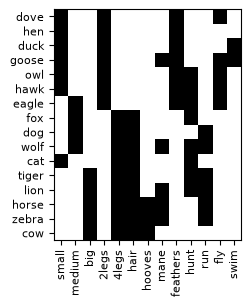

In [5]:
plt.figure(figsize=(3,3))
plt.xticks(np.arange(matrix.shape[1]), animals.columns, rotation=90, fontsize=8)
plt.yticks(np.arange(matrix.shape[0]), animals.index, fontsize=8)
plt.imshow(matrix, cmap='binary')

**Question 1a :** pouvez-vous identifier visuellement des groupes d'animaux ?

# Votre réponse ici :
Oui on arrive a identifer visuellement des groupe d'animaux.

Les **oiseaux** (dove, hen, duck, goose, owl, hawk, eagle) se caractérisent tous par la présence de deux pattes et de plumes.

Les **carnivores** (fox, dog, wolf, cat, tiger, lion) regroupent des animaux à quatre pattes et à poils, qui se définissent tous par leurs aptitudes à la chasse ou à la course, tout en présentant une variation de taille allant du petit au grand.

Les **herbivores** (*horse*, *zebra*, *cow*) rassemblent des animaux de grande taille à quatre pattes et à poils, qui se démarquent par la présence de sabots. 

## 2. Entraînement d'une carte de Kohonen

Le code fourni ci-dessous crée une carte auto-organisatrice, l'entraîne, et affiche le résultat final sous la forme d'une matrice-U.  Veuillez répondre aux questions qui suivent.

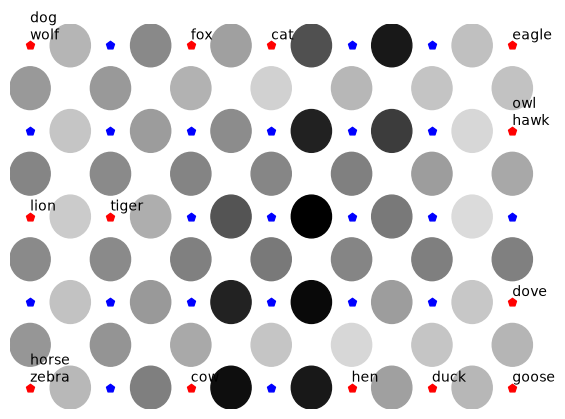

In [6]:
import random
random.seed(1); np.random.seed(1)  # graine fixée pour que la carte soit reproductible

kmap = KohonenUtils.KohonenMap(5, 7, size_vector=len(animals.columns)) # initialiser la SOM

n_iter = 30

learning_rate = KohonenUtils.ExponentialTimeseries(1, 0.2, n_iter * len(animals.index))

neighborhood_size = KohonenUtils.ExponentialTimeseries(4./3 * len(animals.index), 1, n_iter * len(animals.index))

kmap.train(animals.values, np.array(animals.index), n_iter, learning_rate, neighborhood_size) # entraîner la SOM

kmap.plot_umatrix(plot_names=True, plot_empty=True, fontsize=10) # afficher le résultat

**Question 2a :** veuillez expliquer brièvement, avec vos propres mots, ce que représente la matrice U, en répondant aux questions suivantes :
- que représentent les trois paramètres du constructeur `KohonenMap` ?
- que représentent les points bleus ?
- que représentent les points rouges ?
- que représentent les points gris et les niveaux de gris ?
- pour une carte de taille _m_ * _n_, combien y a-t-il de points gris ?

# Votre réponse ici :

La matrice U est une carte qui montre, pour chaque neurone, **où sont placés les animaux** et **à quel point les neurones voisins se ressemblent**. Elle permet de repérer les groupes et les frontières entre eux.

**Les trois paramètres de `KohonenMap(5, 7, size_vector=len(animals.columns))` :**
- `5` : le nombre de lignes de la carte.
- `7` : le nombre de colonnes de la carte (donc 5 × 7 = 35 neurones).
- `size_vector` : la dimension des vecteurs d'entrée, c'est-à-dire le nombre de caractéristiques d'un animal (ici 13). Chaque neurone est un vecteur de cette taille.

**Les points bleus :** ce sont les neurones qui ne sont le plus proche d'aucun animal. Ils sont vides, aucun nom n'y est affiché.

**Les points rouges :** ce sont les neurones qui sont le plus proche d'au moins un animal (neurones gagnants). Le nom de l'animal est écrit à côté, et plusieurs noms indiquent des animaux très semblables.

**Les points gris et les niveaux de gris :** chaque point gris représente la distance entre deux neurones voisins de la carte.
- Gris clair : les deux neurones sont proches, donc les animaux qu'ils représentent se ressemblent (même groupe).
- Gris foncé ou noir : les deux neurones sont éloignés, c'est une **frontière** entre deux groupes.

**Nombre de points gris pour une carte de taille m × n :** il y a un point gris entre chaque paire de neurones voisins :
- m × (n − 1) liaisons horizontales,
- (m − 1) × n liaisons verticales,

soit **2mn − m − n** points gris. Pour la carte 5 × 7 : 70 − 12 = **58**.

**Question 2b :** veuillez régler les paramètres du constructeur `KohonenMap` et le `n_iter` de façon à aboutir à une carte de Kohonen qui regroupe les seize animaux d'une manière qui vous semble cohérente.   Veuillez indiquer ci-dessous les paramètres choisis, lister les groupes observés d'animaux, et commenter le résultat.

# Votre réponse ici :

**Paramètres choisis :** `KohonenMap(5, 7, size_vector=13)` et `n_iter = 30` (graine aléatoire fixée à 1 pour que le résultat soit reproductible). `learning_rate` et `neighborhood_size` restent ceux de l'énoncé.

**Pourquoi ces valeurs :**
- Une carte de 5×7 = 35 neurones pour 16 animaux laisse assez de neurones vides (bleus) pour que les frontières entre groupes apparaissent. Avec une carte trop petite (4×6 ou 5×5), plusieurs animaux se retrouvent sur le même neurone et les distances entre groupes sont moins lisibles.
- Avec `n_iter = 10` (valeur de départ), les groupes sont déjà corrects, mais la carte est moins fine : par exemple hen et duck tombent sur le même neurone. Avec 30 présentations de chaque animal (480 mises à jour), `learning_rate` et `neighborhood_size` ont plus de temps pour décroître lentement, et la carte distingue mieux les animaux proches.

**Groupes observés :**

Ce qui saute directement aux yeux sur la matrice U, ce sont **2 grands groupes** séparés par une grande barrière sombre (frontière rouge sur l'image) :
1. **Les mammifères** (à gauche) : dog+wolf, fox, cat, lion, tiger, horse+zebra, cow.
2. **Les oiseaux** (à droite et en bas à droite) : eagle, owl+hawk, dove, hen, duck, goose.

Cette barrière est logique : un oiseau a 2 pattes et des plumes, un mammifère a 4 pattes et des poils, ce qui fait beaucoup d'attributs différents.

En regardant de plus près, on devine aussi **deux séparations beaucoup plus faibles** (traits orange en pointillé sur l'image), une dans chaque grand groupe :
- **Chez les mammifères**, les **carnivores** (dog+wolf, fox, cat, puis lion et tiger) en haut, et les **grands herbivores** (horse+zebra, cow) en bas à gauche.
- **Chez les oiseaux**, les **oiseaux carnivores, ou rapaces** (eagle, owl+hawk) en haut, et les **oiseaux qui ne chassent pas** (dove, hen, duck, goose) en bas.

Dans les deux cas, la séparation vient surtout du même attribut, `hunt` : les carnivores et les rapaces chassent, les herbivores et les autres oiseaux non. Les données ne contiennent pas d'attribut « herbivore » : c'est donc une interprétation, déduite du fait qu'ils ne chassent pas.

**Documentation (mesures faites sur la carte et sur les données) :**
- **Sur la matrice U :** les cases de la frontière forte valent environ 1 (jusqu'à 1,12), alors que celles des séparations faibles valent environ 0,4 à 0,6, et celles à l'intérieur d'un groupe environ 0,2 à 0,5. Les séparations faibles sont donc visibles, mais peu marquées.
- **Sur les données :** la distance moyenne entre un oiseau et un mammifère est d'environ 2,9, contre 1,7 entre un rapace et un autre oiseau (et 0,9 entre deux rapaces).
- **Sur la carte, avec 8 graines différentes :** les rapaces sont à environ 3 cases des autres oiseaux (entre 2,7 et 3,4), contre environ 1 case entre rapaces (0,7 à 1,3) et 1,4 à 1,9 entre les autres oiseaux. De même, carnivores et herbivores sont à environ 3,6 cases l'un de l'autre, contre 2,1 entre carnivores et 1,3 entre herbivores. Ces séparations apparaissent à chaque graine, donc ce n'est pas un hasard de l'initialisation.

**Commentaire :** ce résultat rejoint ce que nous avions observé au début (question 1a), où nous avions repéré 3 groupes : oiseaux, carnivores et grands herbivores. La carte confirme ces groupes, mais elle montre qu'ils ne sont pas au même niveau : la grande séparation est oiseaux contre mammifères, puis, à l'intérieur de chacun, une subdivision plus faible selon que l'animal chasse ou non. Les paires horse/zebra, dog/wolf et owl/hawk tombent sur le même neurone car leurs descriptions sont (presque) identiques. Enfin, le résultat dépend de l'initialisation aléatoire : d'un entraînement à l'autre, la carte est tournée ou retournée et la position exacte des animaux change, mais on retrouve à chaque fois les mêmes groupes.

**Question 2c :** veuillez afficher une image de la matrice-U, au format PNG ou JPG, sur laquelle vous aurez dessiné les frontières visibles (à la main, avec un logiciel d'édition de votre choix).  Veillez à sauvegarder le notebook avec l'image avant l'envoi sur Cyberlearn.

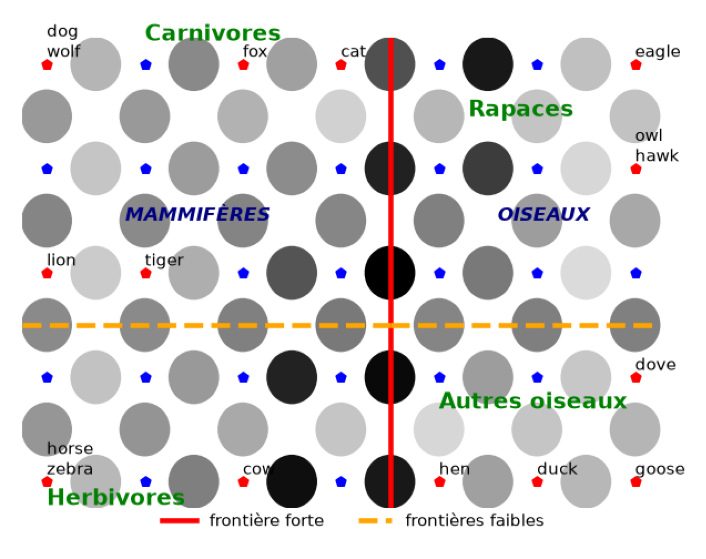

In [7]:
# Pour afficher votre image ici :
plt.figure(figsize=(10, 7))
plt.imshow(mpimg.imread('matrice-u-sakho.png'))
plt.axis('off')
plt.show()

## 3. Analyse des paramètres de l'entraînement

Dans cette section, le but est de comprendre les paramètres `learning_rate` et `neighborhood_size`.  Veuillez ré-exécuter les commandes ci-dessous qui les ré-initialisent.  On vous encourage à faire différents essais avant de répondre.

In [8]:
learning_rate = KohonenUtils.ExponentialTimeseries(1, 0.2, n_iter * len(animals.index))

**Question 3a :** veuillez expliquer avec vos propres mots le fonctionnement de `learning_rate` en répondant aux questions suivantes :
- quel est le type de `learning_rate` ?
- quelles sont les significations de ses trois paramètres ?
- pourquoi la valeur du troisième paramètre est-elle choisie ainsi ?
- comme fonctionne la `learning_rate` ?

# Votre réponse ici :

- **Type de `learning_rate`** : c'est un objet `ExponentialTimeseries` (une série temporelle à décroissance exponentielle). Il se comporte comme une fonction : chaque appel `learning_rate()` renvoie la valeur suivante de la série.
- **Signification des trois paramètres** `ExponentialTimeseries(1, 0.2, n_iter * len(animals.index))` : `1` est la valeur initiale, `0.2` la valeur finale, et le troisième paramètre est le nombre total de valeurs de la série, donc le nombre de pas d'apprentissage.
- **Pourquoi le troisième paramètre est choisi ainsi** : la méthode `learn` est appelée une fois par animal présenté et elle consomme une valeur de `learning_rate` à chaque appel. Comme on présente les 16 animaux `n_iter` fois, il y a exactement `n_iter * 16` appels. Ainsi la série part bien de 1 au premier pas et arrive à 0,2 au dernier.
- **Fonctionnement** : la série est calculée avec `np.linspace` entre `ln(1)` et `ln(0.2)`, puis passée à l'exponentielle. La valeur diminue donc par un même facteur à chaque pas (décroissance exponentielle). Le taux d'apprentissage est le coefficient `eta` de la mise à jour `neurones += eta * poids * (entrée − neurones)`. Au début il est grand : les neurones bougent beaucoup, la carte se déplie. À la fin il est petit : on ne fait que de petits ajustements, la carte se stabilise. Une fois la série épuisée, l'objet renvoie toujours la dernière valeur.

**Question 3b :** veuillez afficher d'une façon convenable la ou les valeur(s) de la `learning_rate`.

Premières valeurs : [1.    0.997 0.993]
Dernières valeurs : [0.201 0.201 0.2  ]


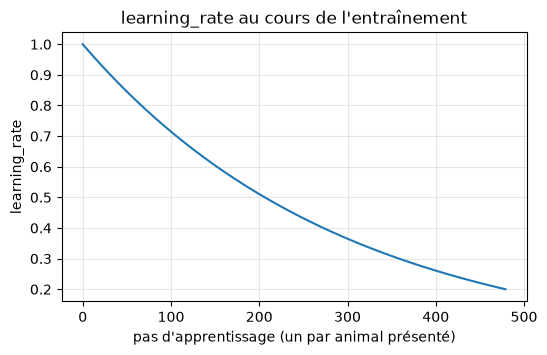

In [9]:
# Votre code pour l'affichage de learning_rate ici :
print("Premières valeurs :", np.round(learning_rate.values[:3], 3))
print("Dernières valeurs :", np.round(learning_rate.values[-3:], 3))
plt.figure(figsize=(6, 3.5))
plt.plot(learning_rate.values)
plt.title("learning_rate au cours de l'entraînement")
plt.xlabel("pas d'apprentissage (un par animal présenté)")
plt.ylabel("learning_rate")
plt.grid(alpha=0.3)
plt.show()

On pose maintenant les mêmes questions pour `neighborhood_size`.  <br/> Si les réponses sont similaires, vous pouvez copier/coller les réponses précédentes.

In [10]:
neighborhood_size = KohonenUtils.ExponentialTimeseries(4./3 * len(animals.index), 1, n_iter * len(animals.index))

**Question 3c :** veuillez expliquer avec vos propres mots le fonctionnement de `neighborhood_size` en répondant aux questions suivantes :
- quel est le type de `neighborhood_size` ?
- quelles sont les significations de ses trois paramètres ?
- comme fonctionne la `neighborhood_size` ?

# Votre réponse ici :

- **Type de `neighborhood_size`** : c'est aussi un `ExponentialTimeseries` : une série à décroissance exponentielle, qui renvoie une nouvelle valeur à chaque appel.
- **Signification des trois paramètres** `ExponentialTimeseries(4./3 * len(animals.index), 1, n_iter * len(animals.index))` : la valeur initiale est `4/3 × 16 ≈ 21,3`, la valeur finale est `1`, et le nombre de valeurs est `n_iter × 16` (une valeur par animal présenté), comme pour `learning_rate`.
- **Fonctionnement** : cette valeur (appelée sigma dans `kohonen.py`) règle la taille du voisinage : autour du neurone gagnant, chaque neurone reçoit un poids de mise à jour qui diminue avec sa distance au gagnant sur la grille, et sigma contrôle la vitesse de cette diminution (le poids est une gaussienne, `exp(−d² / 2σ²)`, où d est la distance sur la grille entre le neurone et le gagnant). Au début sigma est grand (≈ 21 pour une carte de 5×7) : presque tous les neurones se déplacent avec le gagnant, ce qui ordonne la carte globalement. À la fin sigma vaut 1 : seuls le gagnant et ses voisins immédiats bougent, ce qui affine le placement local. Le principe est le même que pour `learning_rate` : on commence par un réglage grossier puis on affine.

**Question 3d :** veuillez afficher d'une façon convenable la ou les valeur(s) de la `neighborhood_size`.

Premières valeurs : [21.333 21.197 21.062]
Dernières valeurs : [1.013 1.006 1.   ]


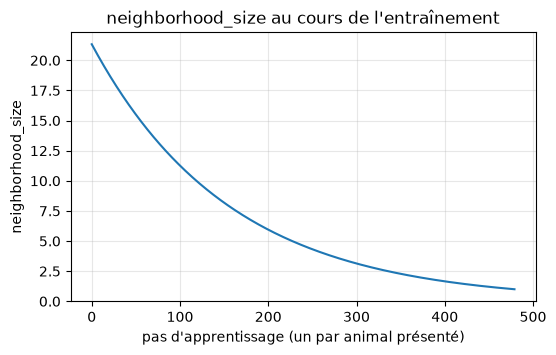

In [11]:
# Votre code pour l'affichage de neighborhood_size ici :
print("Premières valeurs :", np.round(neighborhood_size.values[:3], 3))
print("Dernières valeurs :", np.round(neighborhood_size.values[-3:], 3))
plt.figure(figsize=(6, 3.5))
plt.plot(neighborhood_size.values)
plt.title("neighborhood_size au cours de l'entraînement")
plt.xlabel("pas d'apprentissage (un par animal présenté)")
plt.ylabel("neighborhood_size")
plt.grid(alpha=0.3)
plt.show()

**Fin du Labo.**  Veuillez nettoyer ce notebook, afficher les résultats et les commentaires demandés, l'enregistrer, et le soumettre comme devoir sur Cyberlearn.